#Classificando caracteres utilizando rede MLP.
Este exemplo utiliza a base de dados MNIST, que consiste em imagens de caracteres numéricos escritos à mão.

##Etapa 01
Importar as bibliotecas de aprendizado de máquina e computação científica.

In [22]:
#Bibliotecas de aprendizado de máquina
from tensorflow import keras
from keras.models import Sequential
from keras.layers import Flatten
from keras.layers import Dense
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.metrics import classification_report

#Bibliotecas de computação científica
import numpy as np
import matplotlib.pyplot as plt

##Etapa 02
Importar a base de dados MNIST do keras

Curiosidade: o Keras fornece um conjunto de base de dados para aprendizado. Veja mais em: https://keras.io/api/datasets/

In [2]:
(x_train, y_train), (x_test, y_test) = keras.datasets.mnist.load_data()

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


##Etapa 03
Conhecer e plotar a base de dados

In [3]:
#Verificar a quantidade de dados para treinamento e validação
print('x_train', x_train.shape)
print('y_train', y_train.shape)
print('x_test', x_test.shape)
print('y_test', y_test.shape)


x_train (60000, 28, 28)
y_train (60000,)
x_test (10000, 28, 28)
y_test (10000,)


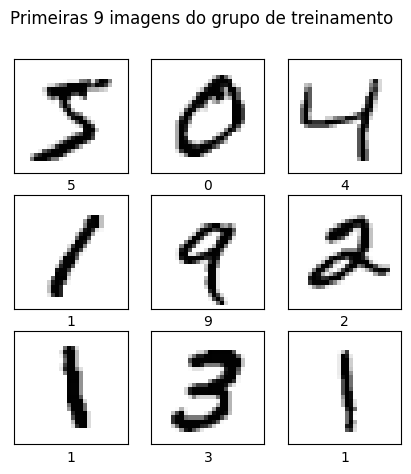

In [4]:
#Plotar imagem
plt.figure(figsize=(5,5))
plt.suptitle('Primeiras 9 imagens do grupo de treinamento')
for i in range(9):
  plt.subplot(3,3,i+1)
  plt.xticks([])
  plt.yticks([])
  plt.grid(False)
  plt.imshow(x_train[i], cmap=plt.cm.binary)
  plt.xlabel(y_train[i])
plt.show()

In [5]:
x_train[0,:,:]

array([[  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   3,
         18,  18,  18, 126, 136, 175,  26, 166, 255, 247, 127,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,  30,  36,  94, 154, 170,
        253, 253, 253, 253, 253, 225, 172, 253, 242, 195,  64,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,  49, 238, 253, 253, 253, 253,
        253, 253, 253, 253, 251,  93,  82,  82,  56,  39,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,  18, 219, 253, 253, 253, 253,
        253, 198, 182, 247, 241,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,  80, 156, 107, 253, 253,
        205,  11,   0,  43, 154,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,  14,   1, 154, 253,
         90,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0, 139, 253,
        190,   2,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,  11, 190,
        253,  70,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,  35,
        241, 225, 160, 108,   1,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         81, 240, 253, 253, 119,  25,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,  45, 186, 253, 253, 150,  27,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,  16,  93, 252, 253, 187,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0, 249, 253, 249,  64,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,  46, 130, 183, 253, 253, 207,   2,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,  39,
        148, 229, 253, 253, 253, 250, 182,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,  24, 114, 221,
        253, 253, 253, 253, 201,  78,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,  23,  66, 213, 253, 253,
        253, 253, 198,  81,   2,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,  18, 171, 219, 253, 253, 253, 253,
        195,  80,   9,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,  55, 172, 226, 253, 253, 253, 253, 244, 133,
         11,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0, 136, 253, 25

In [6]:
y_train

array([5, 0, 4, ..., 5, 6, 8], dtype=uint8)

##Etapa 04
Pré-processar as imagens de forma que os valores de intensidade para os pixels fiquem entre 0 e 1.

In [7]:
x_train = x_train/255
x_test = x_test/255

In [8]:
x_train[0,:,:]

array([[0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        ],
       [0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        ],
       [0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.    

In [9]:
#y_train = keras.utils.to_categorical(y_train, num_classes=10)
#y_test = keras.utils.to_categorical(y_test, num_classes=10)

##Etapa 05
Construir a rede neural utilizando o Keras.

Primeira camada (entrada): transforma o array bidimensional (28,28) para um array unidimensional (28*28=784).

Segunda camada: Uma camada com 128 neurônios.

Terceira camada (saída): implementa uma softmax de 10 nós que retorna um array de 10 probabilidades, cuja soma resulta em 1. Cada nó contém um valor que indica a probabilidade de que aquela imagem pertença a uma das 10 classes.

In [10]:
keras.backend.clear_session()
model = Sequential()
model.add(Flatten(input_shape=(28,28))),
model.add(Dense(128, activation='relu')),
model.add(Dense(10, activation='softmax'))

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

##Etapa 06
Compilar o modelo.

Optimizer: As opções são encontradas em https://keras.io/api/optimizers/

Loss: As opções são encontradas em https://keras.io/api/losses/

Metrics: As opções são encontradas em https://keras.io/api/metrics/

In [11]:
model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['sparse_categorical_accuracy'])

##Etapa 07
Treinar o modelo e realizar a validação.

Epoch 1/30
1875/1875 - 10s - 5ms/step - loss: 0.2618 - sparse_categorical_accuracy: 0.9263 - val_loss: 0.1384 - val_sparse_categorical_accuracy: 0.9598
Epoch 2/30
1875/1875 - 6s - 3ms/step - loss: 0.1166 - sparse_categorical_accuracy: 0.9657 - val_loss: 0.1042 - val_sparse_categorical_accuracy: 0.9667
Epoch 3/30
1875/1875 - 5s - 3ms/step - loss: 0.0793 - sparse_categorical_accuracy: 0.9764 - val_loss: 0.0819 - val_sparse_categorical_accuracy: 0.9739
Epoch 4/30
1875/1875 - 5s - 3ms/step - loss: 0.0594 - sparse_categorical_accuracy: 0.9816 - val_loss: 0.0825 - val_sparse_categorical_accuracy: 0.9748
Epoch 5/30
1875/1875 - 5s - 3ms/step - loss: 0.0466 - sparse_categorical_accuracy: 0.9859 - val_loss: 0.0782 - val_sparse_categorical_accuracy: 0.9764
Epoch 6/30
1875/1875 - 5s - 3ms/step - loss: 0.0363 - sparse_categorical_accuracy: 0.9888 - val_loss: 0.0788 - val_sparse_categorical_accuracy: 0.9766
Epoch 7/30
1875/1875 - 5s - 3ms/step - loss: 0.0296 - sparse_categorical_accuracy: 0.9905 - v

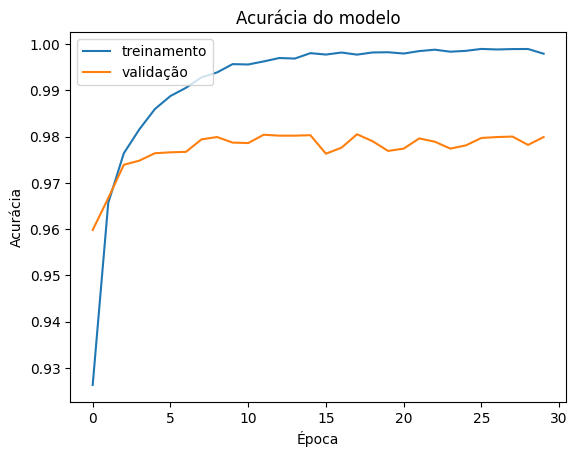

In [12]:
history = model.fit(x_train, y_train, epochs=30, batch_size=32, validation_data=(x_test, y_test), verbose=2)
plt.plot(history.history['sparse_categorical_accuracy'])
plt.plot(history.history['val_sparse_categorical_accuracy'])
plt.title('Acurácia do modelo')
plt.ylabel('Acurácia')
plt.xlabel('Época')
plt.legend(['treinamento', 'validação'], loc='upper left')
plt.show()

##Etapa 08
Realizar algumas predições. Experimente variar a amostra (variável i).

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


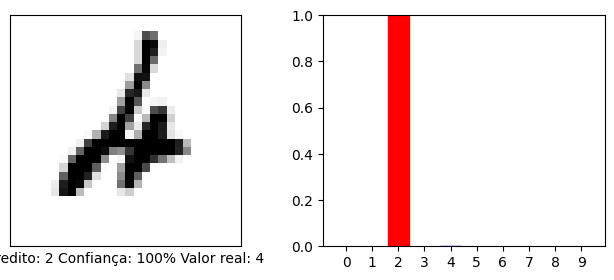

In [13]:
predictions = model.predict(x_test)
class_names = [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
i =247

def plot_image(prediction_array, true_label, img):
  plt.grid(False)
  plt.xticks([])
  plt.yticks([])
  plt.imshow(img, cmap=plt.cm.binary)
  predicted_label = np.argmax(prediction_array)
  plt.xlabel('Predito: {} Confiança: {:2.0f}% Valor real: {}'.format(predicted_label, 100*np.max(prediction_array), true_label))

def plot_rate(prediction_array, true_label):
  plt.grid(False)
  plt.xticks(range(10), class_names)
  thisplot = plt.bar(range(10), prediction_array, color="#777777")
  plt.ylim([0, 1])
  predicted_label = np.argmax(prediction_array)
  thisplot[predicted_label].set_color('red')
  thisplot[true_label].set_color('blue')

plt.figure(figsize=(8,3))
plt.subplot(1,2,1)
plot_image(predictions[i], y_test[i], x_test[i])
plt.subplot(1,2,2)
plot_rate(predictions[i], y_test[i])
plt.show()


In [14]:
print(predictions[247])

[8.1434656e-14 4.7680093e-16 9.9728155e-01 7.2159043e-11 1.4979243e-07
 1.1669839e-11 2.7182687e-03 1.9925025e-12 2.7413274e-10 1.1735398e-22]


##Etapa 09
Encontrar todas as predições erradas.

In [15]:
error_classification = []

for i in range(len(predictions)):
  if (np.argmax(predictions[i]) != y_test[i]):
    error_classification.append(i)

print('Total de predições erradas: ', len(error_classification))
print('Lista das predições erradas: ', error_classification)

Total de predições erradas:  201
Lista das predições erradas:  [119, 247, 274, 340, 381, 445, 492, 495, 613, 619, 684, 691, 696, 720, 846, 882, 900, 938, 951, 956, 1003, 1014, 1039, 1050, 1112, 1156, 1166, 1182, 1226, 1232, 1242, 1247, 1260, 1319, 1328, 1393, 1395, 1500, 1520, 1522, 1530, 1549, 1554, 1609, 1621, 1642, 1681, 1722, 1790, 1871, 1878, 1901, 1940, 1941, 1982, 1984, 2018, 2024, 2033, 2035, 2043, 2098, 2109, 2135, 2182, 2272, 2280, 2293, 2325, 2339, 2369, 2387, 2488, 2582, 2607, 2635, 2648, 2654, 2720, 2742, 2836, 2907, 2915, 2921, 2939, 2952, 2953, 3021, 3060, 3062, 3073, 3117, 3172, 3225, 3422, 3503, 3520, 3550, 3558, 3604, 3681, 3727, 3751, 3776, 3780, 3808, 3811, 3818, 3853, 3869, 3902, 3906, 3941, 3943, 4065, 4078, 4123, 4140, 4163, 4199, 4201, 4248, 4289, 4294, 4425, 4433, 4497, 4536, 4571, 4639, 4761, 4807, 4823, 4874, 4879, 4880, 4956, 5165, 5331, 5457, 5623, 5642, 5676, 5734, 5749, 5887, 5936, 5937, 5955, 5973, 6009, 6011, 6023, 6045, 6059, 6101, 6166, 6555, 6571, 65

In [16]:
x_test[1].shape

(28, 28)

#Informação complementar
##Realizar a predição de uma única imagem

Na Etapa 08, realizamos a predição de todas as amostras de validação e plotamos o resultado de uma única amostra para visualização, isso porque o Keras é otimizado para trabalhar com batch (coleções) de dados. Para realizar a predição de uma única imagem, os passos abaixo são necessários.

In [17]:
#Escolha da imagem
img_selected = 321
img = x_test[img_selected]
print(img.shape)


(28, 28)


Como o Keras trabalha com batch, é preciso adicionar a imagem desejada em uma lista cujo único elemento seja a imagem que se deseja predizer. Para isso, basta expandir as dimensões da imagem para 3, sendo o primeiro elemento a posição na lista.

In [18]:
#reshape
img = (np.expand_dims(img,0))
print(img.shape)

(1, 28, 28)


Com a única imagem na lista, é possível realizar a sua predição.

In [19]:
value_predicted = model.predict(img)
print(value_predicted)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 375ms/step
[[3.3114637e-17 1.4184219e-10 9.2716593e-01 4.8485612e-07 1.3897625e-28
  5.3413844e-20 9.2770239e-19 7.2831467e-02 2.0704510e-06 7.2171588e-11]]


Por fim, encontramos a maior probabilidade e exibimos o resultado, como na Etapa 08

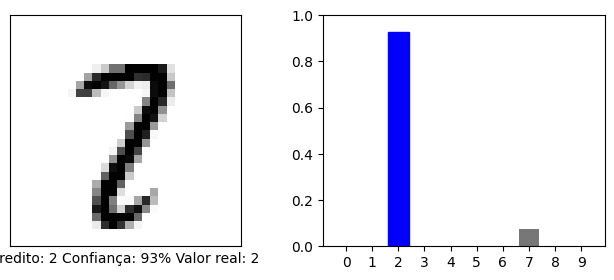

In [20]:
plt.figure(figsize=(8,3))
plt.subplot(1,2,1)
plot_image(value_predicted, y_test[img_selected], x_test[img_selected])
plt.subplot(1,2,2)
plot_rate(value_predicted[0], y_test[img_selected])
plt.show()

#Análise das métricas

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step


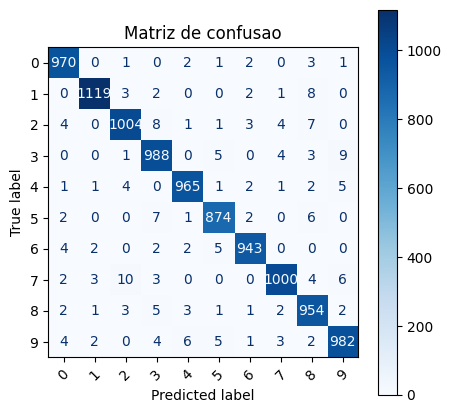

              precision    recall  f1-score   support

           0       0.98      0.99      0.99       980
           1       0.99      0.99      0.99      1135
           2       0.98      0.97      0.98      1032
           3       0.97      0.98      0.97      1010
           4       0.98      0.98      0.98       982
           5       0.98      0.98      0.98       892
           6       0.99      0.98      0.99       958
           7       0.99      0.97      0.98      1028
           8       0.96      0.98      0.97       974
           9       0.98      0.97      0.98      1009

    accuracy                           0.98     10000
   macro avg       0.98      0.98      0.98     10000
weighted avg       0.98      0.98      0.98     10000



In [25]:
y_pred_prob = model.predict(x_test)

# Converte as probabilidades em classes discretas (0, 1, 2, ..., 9)
y_pred = np.argmax(y_pred_prob, axis=1)

# Matriz de confusao (linhas = classe real, colunas = classe prevista)

cm = confusion_matrix(y_test, y_pred, labels=range(10))

fig, ax = plt.subplots(figsize=(5, 5))
disp = ConfusionMatrixDisplay(confusion_matrix=cm,
                              display_labels=class_names)
disp.plot(cmap='Blues', ax=ax, xticks_rotation=45)
plt.title('Matriz de confusao')
plt.show()

# Precisao, recall e F1 por classe (convertendo class_names para strings para evitar o erro de len)
print(classification_report(y_test, y_pred, labels=range(10), target_names=[str(x) for x in class_names], zero_division=0))